# ЛР 6. Ансамбль конформеров бутана

**Сущность:** Сгенерировать несколько геометрий и проверить покрытие, параметры и сходимость.

**Данные:** Бутан CCCC; геометрии создаются ETKDGv3, seed=42, до 20 стартов.

**Workflow:** Граф → H → параметры → embedding → MMFF → статусы → SDF и энергия.

Перед запуском прочитайте [guideline](../guides/lab06.md) и [теорию](../../Module_theory/Module%206_Moleculr%20mechanics.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [1]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab06"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Проверьте наличие MMFF-параметров и задайте seed.
2. Создайте ансамбль и сохраните статус каждой оптимизации.
3. Сравните только сошедшиеся энергии одной системы; выгрузите SDF.

Ожидаемое: Есть хотя бы один конформер; все записанные энергии конечны; статус несходимости не скрыт; минимальная энергия бутана около −5,1…−4 ккал/моль при найденном наборе, не жёсткая универсальная константа.

,conf_id,status,energy_kcal_mol
0,0,0,-4.293764
1,1,0,-4.293764
2,2,0,-5.075973
3,3,0,-4.293764


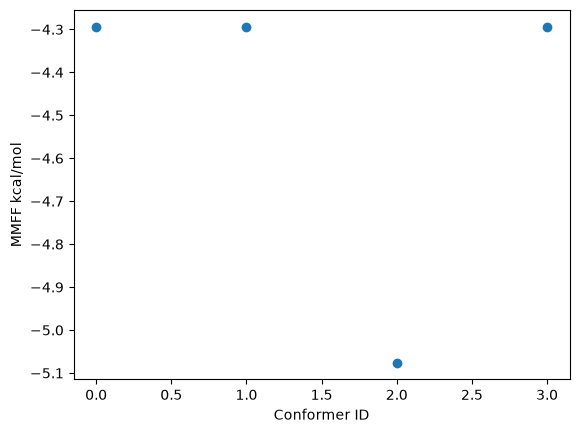

In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem
mol=Chem.AddHs(Chem.MolFromSmiles("CCCC"))
assert AllChem.MMFFHasAllMoleculeParams(mol)
params=AllChem.ETKDGv3();params.randomSeed=42;params.pruneRmsThresh=0.1
ids=list(AllChem.EmbedMultipleConfs(mol,numConfs=20,params=params))
optimization=AllChem.MMFFOptimizeMoleculeConfs(mol,numThreads=1,maxIters=500)
ensemble=pd.DataFrame([{"conf_id":i,"status":status,"energy_kcal_mol":energy} for i,(status,energy) in zip(ids,optimization)])
display(ensemble)
assert len(ids)>0
assert np.isfinite(ensemble.energy_kcal_mol).all()
assert (ensemble.status==0).any()
with Chem.SDWriter(str(OUT/"butane_conformers.sdf")) as writer:
    for row in ensemble.itertuples():
        mol.SetProp("MMFF_status",str(row.status));mol.SetProp("MMFF_energy_kcal_mol",str(row.energy_kcal_mol))
        writer.write(mol,confId=int(row.conf_id))
ensemble.to_csv(OUT/"energies.csv",index=False)
plt.scatter(ensemble.conf_id,ensemble.energy_kcal_mol);plt.xlabel("Conformer ID");plt.ylabel("MMFF kcal/mol")
plt.savefig(OUT/"conformers.png",dpi=150);plt.show()
artifact={"generated":len(ids),"converged":int((ensemble.status==0).sum()),"minimum":float(ensemble.energy_kcal_mol.min()),"seed":42}


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [3]:
elapsed = time.perf_counter()-started
run_record = {"lab": 6, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\Labs\results\lab06\benchmark.json


## 4. Самостоятельная тренировка

1. Повторите с seed=7; сравните число геометрий и диапазон энергий.
2. Объясните, почему лучший найденный минимум не гарантированно глобальный.
3. Выведите торсионный угол одной конформации и отличите его от поворота камеры.

[Ответы после попытки](../solutions/lab06.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.